# Projet 1 — Analyse des journaux d'un pare-feu
**Fall Madiagne**

 

## 1. Chargement et aperçu

In [1]:
import pandas as pd
from IPython.display import Image, display
import analyse

brut = pd.read_csv(analyse.CSV)
print(brut.shape)
brut.head()

(5500, 9)


,timestamp,src_ip,dst_ip,dst_port,protocol,bytes_sent,duration_s,device_type,action
0,2026-10-05 00:05:13,192.168.1.30,10.0.0.6,80,TCP,7257.0,0.63,capteur_IoT,ALLOW
1,2026-10-05 00:05:43,192.168.1.10,10.0.0.5,80,TCP,1720.0,1.62,capteur_IoT,ALLOW
2,2026-10-05 00:10:45,192.168.1.26,1.1.1.1,1883,TCP,6951.0,4.22,camera_IoT,ALLOW
3,2026-10-05 00:12:25,192.168.1.13,10.0.0.6,80,TCP,3144.0,0.16,capteur_IoT,ALLOW
4,2026-10-05 00:12:34,192.168.1.15,10.0.0.5,8080,TCP,879.0,2.71,serveur,ALLOW


In [2]:
print('Doublons exacts :', brut.duplicated().sum())
print('Valeurs manquantes :')
print(brut.isna().sum())
brut['protocol'].value_counts()

Doublons exacts : 60
Valeurs manquantes :
timestamp        0
src_ip           0
dst_ip           0
dst_port         0
protocol         0
bytes_sent     166
duration_s       0
device_type      0
action           0
dtype: int64


protocol
TCP     4347
UDP      727
tcp      235
ICMP     150
udp       36
icmp       5
Name: count, dtype: int64

## 2. Nettoyage
1. suppression des doublons exacts
2. `protocol` en majuscules
3. `bytes_sent` manquants remplacés par la médiane (calculée après suppression des doublons)

In [3]:
df = analyse.nettoyer(brut)
print(df.shape)
print(df['protocol'].value_counts())
print('Manquants bytes_sent :', df['bytes_sent'].isna().sum())

(5440, 9)
protocol
TCP     4526
UDP      760
ICMP     154
Name: count, dtype: int64
Manquants bytes_sent : 0


## 3. Résultats

In [4]:
res = analyse.calculer_resultats(df)
res

{'nb_lignes_apres_nettoyage': 5440,
 'top_port': 443,
 'taux_deny_pct': 13.57,
 'ip_scanner': '192.168.1.99',
 'ip_exfiltration': '192.168.1.11'}

In [5]:
# Preuve du scan : nombre de ports distincts par IP source
df.groupby('src_ip')['dst_port'].nunique().sort_values(ascending=False).head(5)

src_ip
192.168.1.99    328
192.168.1.11      8
192.168.1.39      8
192.168.1.38      8
192.168.1.36      8
Name: dst_port, dtype: int64

In [6]:
# Preuve de l'exfiltration : octets envoyés par IP source
df.groupby('src_ip')['bytes_sent'].sum().sort_values(ascending=False).head(5)

src_ip
192.168.1.11    259932541.0
192.168.1.25       627582.0
192.168.1.18       626359.0
192.168.1.30       585169.0
192.168.1.34       553399.0
Name: bytes_sent, dtype: float64

## 4. Figures
Le script les enregistre dans `figures/` ; on les affiche ici.

connexions_par_heure.png


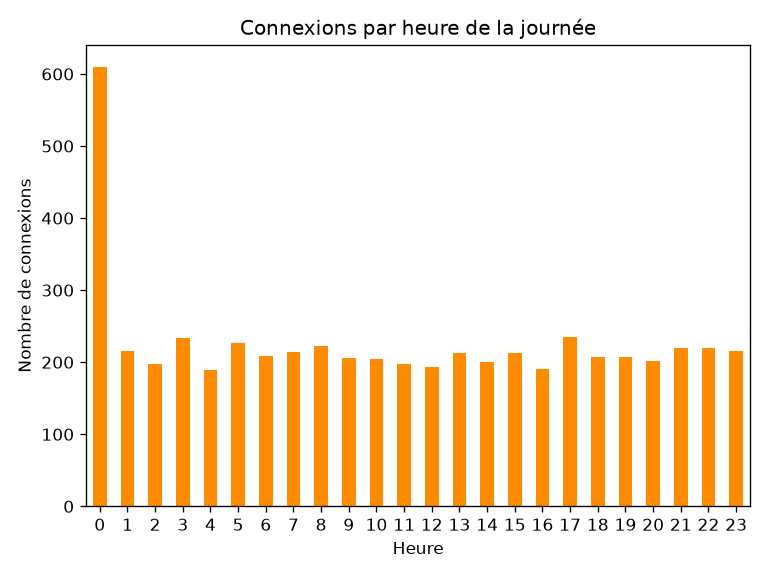

connexions_par_jour.png


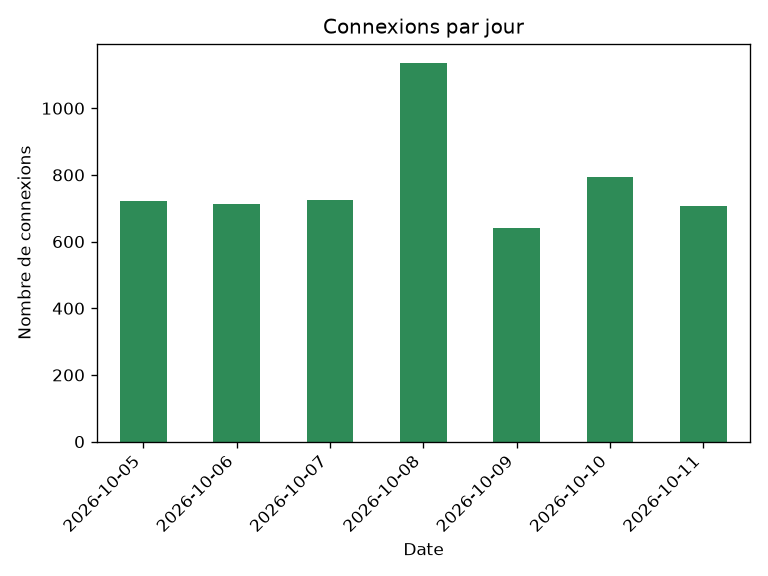

octets_par_appareil.png


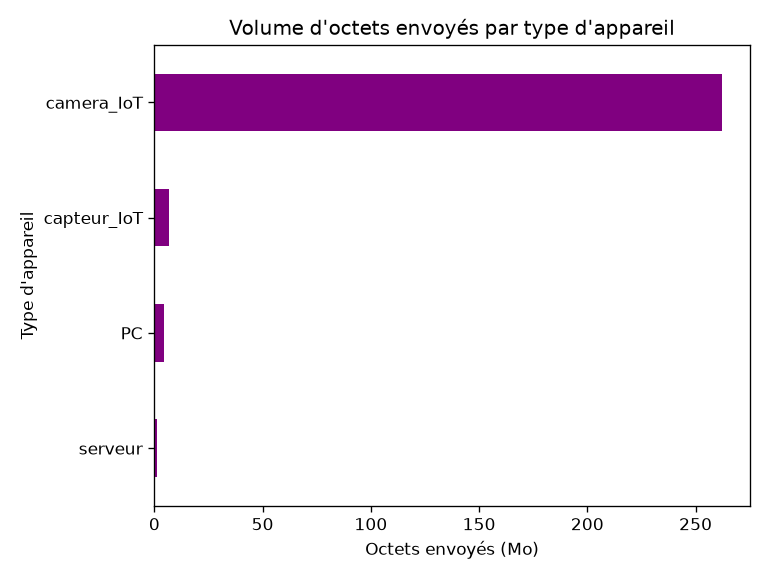

octets_par_ip.png


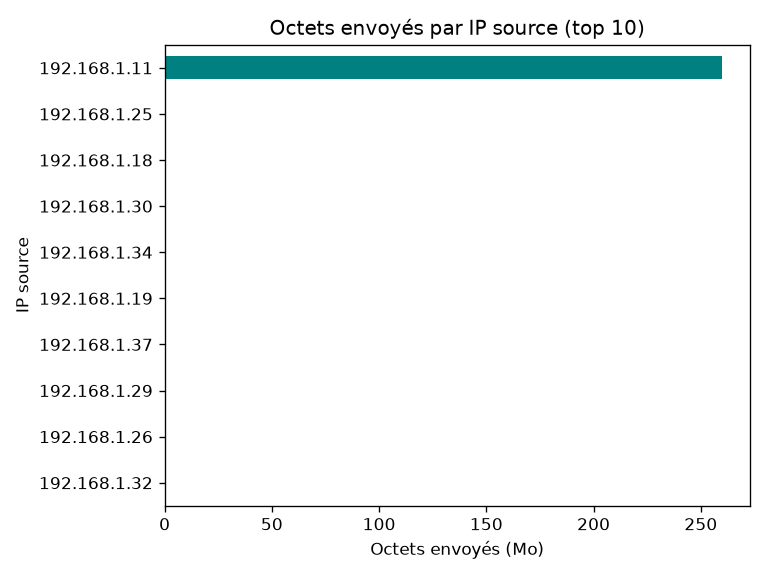

ports_distincts_par_ip.png


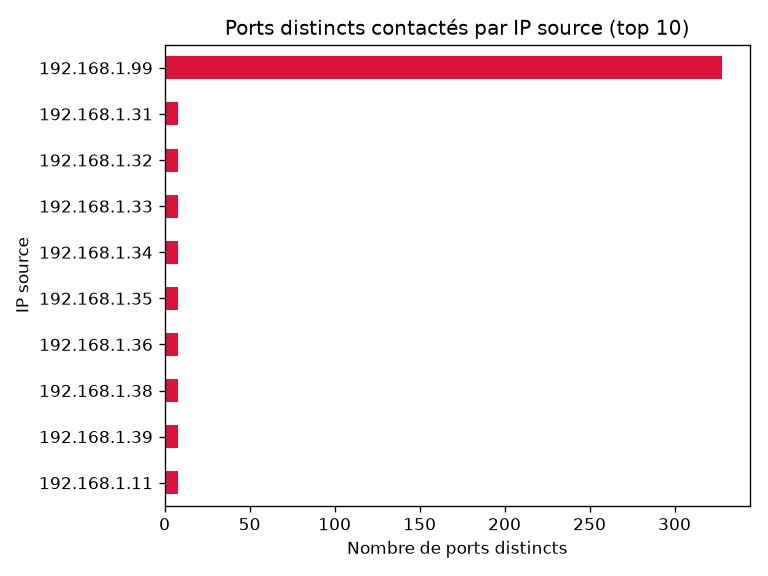

repartition_allow_deny.png


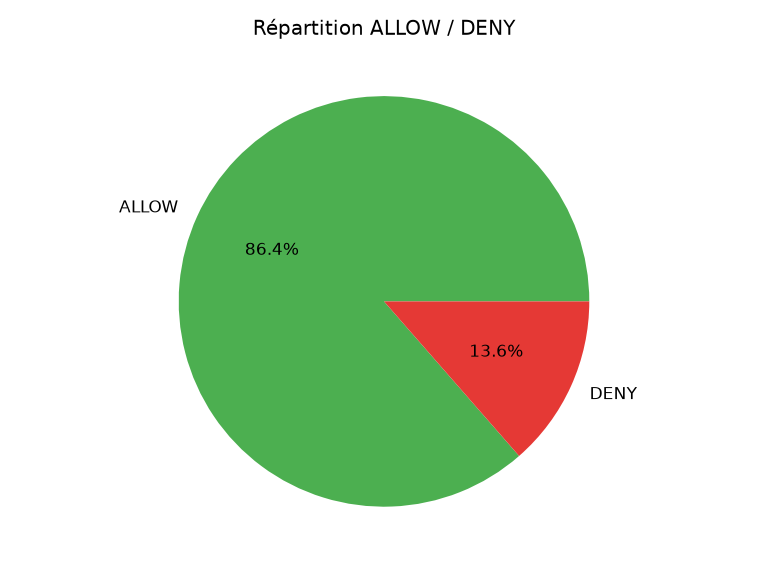

top_ports.png


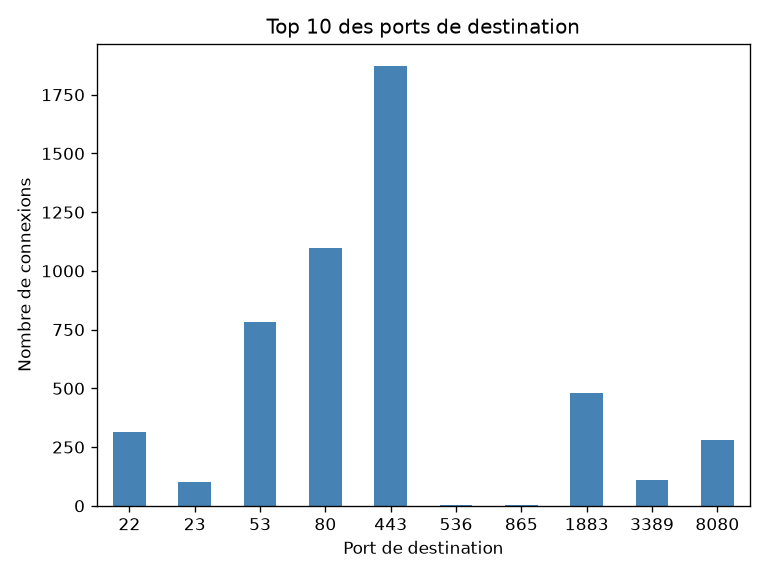

In [7]:
import json
analyse.figures(df, res)
with open('resultats.json', 'w', encoding='utf-8') as f:
    json.dump(res, f, indent=2, ensure_ascii=False)
for nom in sorted(analyse.FIG_DIR.glob('*.png')):
    print(nom.name)
    display(Image(filename=str(nom)))

## 5. Interprétation
Voir `rapport.md` : scan de ports depuis 192.168.1.99 (328 ports distincts, rafale à minuit le 8 octobre) et exfiltration depuis la caméra 192.168.1.11 (≈ 260 Mo, ≈ 95 % du volume).